In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

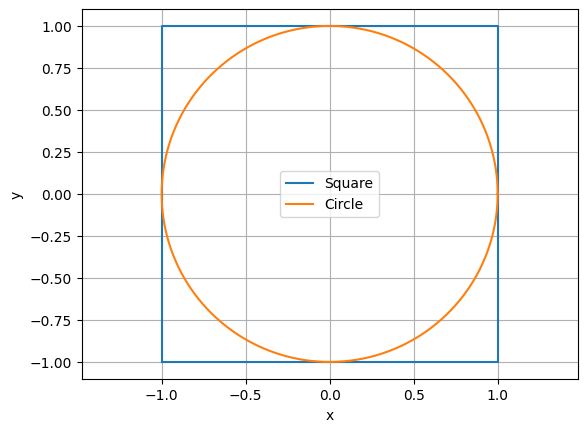

In [2]:
# Define the square
square_x = [-1, 1, 1, -1, -1]
square_y = [-1, -1, 1, 1, -1]

# Define the circle
theta = np.linspace(0, 2*np.pi, 500)
circle_x = np.cos(theta)
circle_y = np.sin(theta)

# Plot both
plt.plot(square_x, square_y, label="Square")
plt.plot(circle_x, circle_y, label="Circle")

plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

In [3]:
def picalc(n_samples=1000): 
    x = np.random.uniform(-1, 1, n_samples)
    y = np.random.uniform(-1, 1, n_samples)
    c = x**2 + y**2
    piby4 = (c <1).sum()/n_samples
    pi_estimated = 4*piby4
    return pi_estimated

In [12]:
n_runs = 200
results = np.array([picalc() for ii in range(n_runs)])

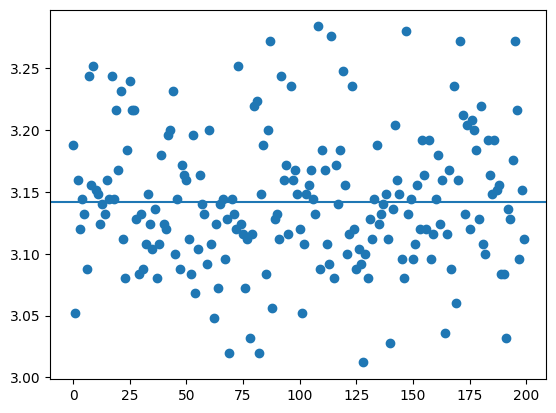

In [13]:
plt.plot(results, linewidth=0, marker='o')
plt.axhline(np.pi)

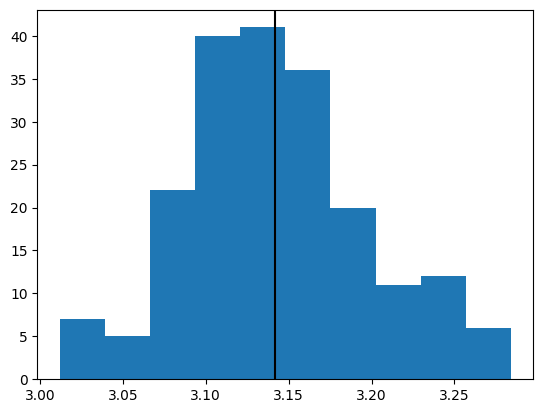

In [14]:
plt.hist(results)
plt.axvline(np.pi, color = 'black')

In [ ]:
mean_pi = np.mean(results)

bias = mean_pi - np.pi

mae = np.mean(np.abs(results - np.pi))

rmse = np.sqrt(np.mean((results - np.pi)**2))


std_dev = np.std(results, ddof=1)


print(f"True pi:              {np.pi:.6f}")

print(f"Mean estimate:        {mean_pi:.6f}")

print(f"Bias:                 {bias:.6f}")

print(f"Mean absolute error:  {mae:.6f}")

print(f"RMSE:                 {rmse:.6f}")

print(f"Sample standard dev.: {std_dev:.6f}")


True pi:              3.141593
Mean estimate:        3.142960
Bias:                 0.001367
Mean absolute error:  0.042680
RMSE:                 0.054915
Sample standard dev.: 0.055036


In [21]:
mu_fit, sigma_fit = stats.norm.fit(results)

print(f"Fitted mean:      {mu_fit:.6f}")

print(f"Fitted stdev:    {sigma_fit:.6f}")

Fitted mean:      3.142960
Fitted stdev:    0.054898


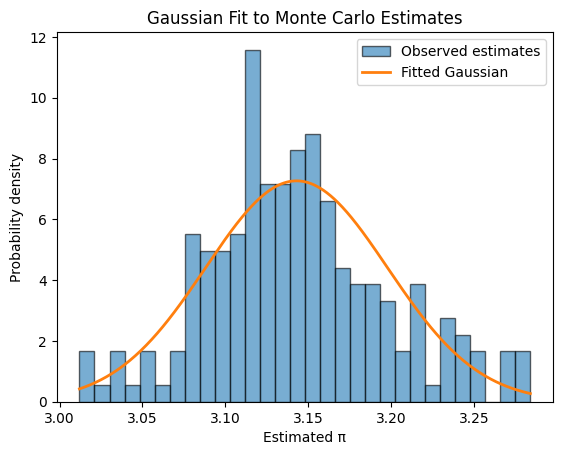

In [22]:
x = np.linspace(results.min(), results.max(), 500)

plt.hist(results, bins=30, density=True,

         alpha=0.6, edgecolor="black", label="Observed estimates")

plt.plot(x, stats.norm.pdf(x, mu_fit, sigma_fit),

         linewidth=2, label="Fitted Gaussian")

plt.xlabel("Estimated π")

plt.ylabel("Probability density")

plt.title("Gaussian Fit to Monte Carlo Estimates")

plt.legend()

plt.show()